![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Módulo 4 · Principales aplicaciones

**Propósito:** Relacionar problemas reales con clasificación, detección, segmentación o reconocimiento.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Leer lo siguiente:
En un taller de producción, una cámara no resuelve el problema por sí sola. Debemos definir **qué se observará**, **qué decisión se necesita** y **cómo verificaremos si esa decisión es correcta**.

| Sector | Problema | Técnica sugerida | Resultado esperado |
|---|---|---|---|
| Manufactura | Contar piezas | Segmentación + contornos | Conteo automático |
| Transporte | Observar semáforos | Segmentación por color | Estado de luz detectada |
| Agricultura | Encontrar zonas amarillas en hojas | Segmentación | Área marcada |
| Logística | Distinguir símbolos impresos | Reconocimiento de patrones | Categoría del símbolo |
| Salud | Asistencia a análisis de imágenes | Modelos validados + supervisión | Apoyo, nunca diagnóstico autónomo en esta práctica |

### Mini demostración: medir el porcentaje de píxeles segmentados

Área coloreada: 14.78% de la imagen


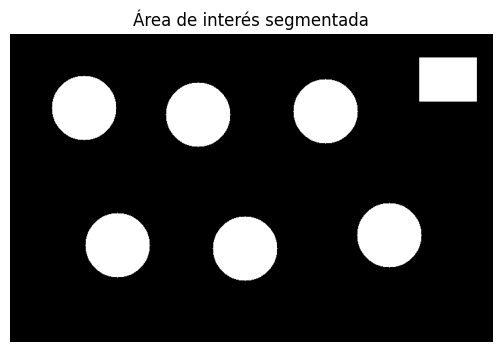

In [2]:
imagen = cv2.imread(str(RECURSOS / 'piezas.png'))
hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
# La saturación discrimina figuras coloreadas del fondo gris.
mascara = cv2.inRange(hsv[:, :, 1], 70, 255)
total = mascara.size
seleccionados = cv2.countNonZero(mascara)
porcentaje = seleccionados / total * 100
print(f'Área coloreada: {porcentaje:.2f}% de la imagen')
mostrar(mascara, 'Área de interés segmentada', gris=True)

### Para dialogar
¿Por qué el porcentaje de la imagen **no equivale** necesariamente al porcentaje real del producto? Influyen la perspectiva, el encuadre y la escala.

**Actividad en parejas:** elijan una aplicación para una empresa cercana, describan cámara/imagen, entrada, operación y salida. No es necesario usar IA neuronal si una regla simple resuelve el problema.

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Por qué los porcentajes pueden diferir?** La cámara ve una proyección: perspectiva, distancia y fondo cambian el área visible.  
**Actividad en parejas:** Centro de acopio agrícola (caso hipotético). Cámara RGB; entrada: imagen de fruto; proceso: segmentación HSV; salida: proporción de colores y revisión humana.

## Ejecución del reto del estudiante (actividad resuelta)

In [3]:
# Actividad en parejas: una aplicación de visión computacional en Satipo.
propuesta={
    'empresa':'Centro de acopio agrícola (caso hipotético)',
    'camara':'Cámara RGB con iluminación controlada frente a la mesa de recepción',
    'entrada':'Fotografía de un fruto en una bandeja',
    'operacion':'Convertir a HSV, segmentar una región por color y medir proporciones',
    'salida':'Porcentaje de área verde/amarilla y aviso para revisión humana',
    'limitaciones':'Sombras, reflejos, color de fondo, variedades y madurez no validada'
}
for k,v in propuesta.items():print(k.title()+':',v)

Empresa: Centro de acopio agrícola (caso hipotético)
Camara: Cámara RGB con iluminación controlada frente a la mesa de recepción
Entrada: Fotografía de un fruto en una bandeja
Operacion: Convertir a HSV, segmentar una región por color y medir proporciones
Salida: Porcentaje de área verde/amarilla y aviso para revisión humana
Limitaciones: Sombras, reflejos, color de fondo, variedades y madurez no validada


### Conclusión y evaluación

Actividad propuesta para una cooperativa hipotética de Satipo. No se afirma que una empresa real instaló la cámara. Una regla simple puede facilitar una revisión inicial, pero el color no determina por sí solo la madurez ni la calidad agronómica.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.